<h1 style="font-family: 'Times New Roman'; text-align: center;"><b>Machine Learning</b></h1>

<h2 style="font-family: 'Times New Roman'; text-align: center;"><b>URL Phishing Detection Project</b></h2>

<h3 style="font-family: 'Times New Roman'; text-align: right;"><b>- Pallav Biyala (24110234)</b></h3>

<HR></HR>

<h2 style="font-family: 'Times New Roman'; text-align: center;"><b> Exploratory Data Analysis</b></h2>

### Objective

#### Understand the PhiUSIIL dataset before applying any machine learning algorithm.

### Importing Libraries

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Reading Dataset

In [12]:
df = pd.read_csv("../data/PhiUSIIL_Phishing_URL_Dataset.csv")
df

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.000000,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.000000,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.000000,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.000000,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.000000,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235790,660997.txt,https://www.skincareliving.com,29,www.skincareliving.com,22,0,com,100.000000,1.000000,0.522907,...,1,0,1,51,7,21,187,2,191,1
235791,77185.txt,https://www.winchester.gov.uk,28,www.winchester.gov.uk,21,0,uk,100.000000,0.785714,0.028555,...,1,0,0,50,1,7,88,0,31,1
235792,622132.txt,https://www.nononsensedesign.be,30,www.nononsensedesign.be,23,0,be,100.000000,1.000000,0.003319,...,0,0,1,27,10,30,58,2,67,1
235793,7503962.txt,https://patient-cell-40f5.updatedlogmylogin.wo...,55,patient-cell-40f5.updatedlogmylogin.workers.dev,47,0,dev,28.157537,0.465116,0.000961,...,0,0,0,0,0,3,0,0,0,0


## Dataset - Level EDA:

### Looking at the distribution of both classes:

In [13]:
# 1 --> Legitimate
# 0 --> Phishing (malicious)
print(df["label"].value_counts())
print(df["label"].value_counts(normalize = True))

label
1    134850
0    100945
Name: count, dtype: int64
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64


In [14]:
print("Total rows:", len(df))
print("Unique URLs:", df["URL"].nunique())
print("Duplicate URLs:", df["URL"].duplicated().sum())

Total rows: 235795
Unique URLs: 235370
Duplicate URLs: 425


In [15]:
print(df.select_dtypes(include=["object", "string"]).columns.tolist())

['FILENAME', 'URL', 'Domain', 'TLD', 'Title']


In [16]:
print(df.dtypes.value_counts())
print(df.columns.tolist())

int64      41
float64    10
str         5
Name: count, dtype: int64
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']


In [17]:
print(df["URLSimilarityIndex"].describe())

count    235795.000000
mean         78.430778
std          28.976055
min           0.155574
25%          57.024793
50%         100.000000
75%         100.000000
max         100.000000
Name: URLSimilarityIndex, dtype: float64


In [18]:
print(
    df.groupby("label")["URLSimilarityIndex"]
      .describe()
)

          count        mean        std         min         25%         50%  \
label                                                                        
0      100945.0   49.616973  22.572082    0.155574   32.120613   51.419332   
1      134850.0  100.000000   0.000000  100.000000  100.000000  100.000000   

              75%    max  
label                     
0       67.251462  100.0  
1      100.000000  100.0  


### Let's look at features

In [19]:
### Printing all features
for i, col in enumerate(df.columns):
    print(f"{i}: {col}")
## As per the dataset provided, we can ignore FILENAME

0: FILENAME
1: URL
2: URLLength
3: Domain
4: DomainLength
5: IsDomainIP
6: TLD
7: URLSimilarityIndex
8: CharContinuationRate
9: TLDLegitimateProb
10: URLCharProb
11: TLDLength
12: NoOfSubDomain
13: HasObfuscation
14: NoOfObfuscatedChar
15: ObfuscationRatio
16: NoOfLettersInURL
17: LetterRatioInURL
18: NoOfDegitsInURL
19: DegitRatioInURL
20: NoOfEqualsInURL
21: NoOfQMarkInURL
22: NoOfAmpersandInURL
23: NoOfOtherSpecialCharsInURL
24: SpacialCharRatioInURL
25: IsHTTPS
26: LineOfCode
27: LargestLineLength
28: HasTitle
29: Title
30: DomainTitleMatchScore
31: URLTitleMatchScore
32: HasFavicon
33: Robots
34: IsResponsive
35: NoOfURLRedirect
36: NoOfSelfRedirect
37: HasDescription
38: NoOfPopup
39: NoOfiFrame
40: HasExternalFormSubmit
41: HasSocialNet
42: HasSubmitButton
43: HasHiddenFields
44: HasPasswordField
45: Bank
46: Pay
47: Crypto
48: HasCopyrightInfo
49: NoOfImage
50: NoOfCSS
51: NoOfJS
52: NoOfSelfRef
53: NoOfEmptyRef
54: NoOfExternalRef
55: label


#### URL Length

In [20]:
# So let's see how URLs are classfied based on basic features like Length, domain etc
df.groupby("label")["URLLength"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100945.0,45.720293,61.145523,13.0,26.0,34.0,48.0,6097.0
1,134850.0,26.228610,4.815612,15.0,23.0,26.0,29.0,57.0


#### So, one obersavtion that Phishing URLs seem to be bigger in length.

#### Domain Length

In [21]:
df.groupby("label")["DomainLength"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100945.0,24.465144,12.204054,4.0,16.0,22.0,29.0,110.0
1,134850.0,19.228610,4.815612,8.0,16.0,19.0,22.0,50.0


#### So, again Domain length seem to be a little bigger for Phishing URLs wrt legitimate ones. But difficult to differentiate on basis of thsi only

#### Sub Domain length

In [22]:
df.groupby("label")["NoOfSubDomain"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100945.0,1.168894,0.790880,0.0,1.0,1.0,1.0,10.0
1,134850.0,1.161661,0.404076,1.0,1.0,1.0,1.0,4.0


#### Quite similair!

#### HTTPS used:

In [23]:
df.groupby("label")["IsHTTPS"].mean()

label
0    0.492238
1    1.000000
Name: IsHTTPS, dtype: float64

#### So one thing sure, if HTTPS not used, defiently phishing URL. but if used --> need other features

### Data Quality:

#### Missing Check:

In [24]:
print("Missing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

Missing Values:
FILENAME                0
URL                     0
URLLength               0
Domain                  0
DomainLength            0
IsDomainIP              0
TLD                     0
URLSimilarityIndex      0
CharContinuationRate    0
TLDLegitimateProb       0
URLCharProb             0
TLDLength               0
NoOfSubDomain           0
HasObfuscation          0
NoOfObfuscatedChar      0
ObfuscationRatio        0
NoOfLettersInURL        0
LetterRatioInURL        0
NoOfDegitsInURL         0
DegitRatioInURL         0
dtype: int64


#### No Missing data

#### Duplicate Check:

In [25]:
print("\nDuplicate rows:", df.duplicated().sum())

print("FILENAME unique:", df["FILENAME"].is_unique)
print("Duplicate rows ignoring FILENAME:",
      df.duplicated(subset=df.columns.drop("FILENAME")).sum())

print("Duplicate URLs:", df["URL"].duplicated().sum())

url_label_counts = df.groupby("URL")["label"].nunique()
print("URLs with conflicting labels:", (url_label_counts > 1).sum())

duplicate_urls = df[df["URL"].duplicated(keep=False)]
print("Rows belonging to repeated URLs:", len(duplicate_urls))
print("Unique repeated URLs:", duplicate_urls["URL"].nunique())


Duplicate rows: 0
FILENAME unique: True
Duplicate rows ignoring FILENAME: 0
Duplicate URLs: 425
URLs with conflicting labels: 0
Rows belonging to repeated URLs: 850
Unique repeated URLs: 425


#### So no duplicate Rows but we can see we have 425 duplicated URLs each appearing twice. It still shows 0 duplicated rows just because we have other parameters like FILENAME, LineOfCode etc. that make the row unqiue. So, to have a fair test, we can remove these one of the two duplciated URLs from the dataset (if required)

#### Data types

In [26]:
print("\nData Types:")
print(df.dtypes.value_counts())


Data Types:
int64      41
float64    10
str         5
Name: count, dtype: int64


#### So this means we have to deal mostly with 50 features + 1 label. String-valued features will be investigated separately. Some information may overlap with the engineered numerical features, while the raw strings may also contain additional semantic information. Their inclusion will therefore be decided after further analysis. 

<hr>

## Feature - Level EDA:

#### So since we begin with simplistic herusitic that string valued features are already taken care by the numerical features and so we dont have to hot-code them, let's form the dataset of our only numerical features

In [27]:
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.drop("label") # so features dont have label (target) so drop that

print("Number of numerical features:", len(numerical_features))
for i,feature in enumerate(numerical_features):
    print(i, ":", feature)

Number of numerical features: 50
0 : URLLength
1 : DomainLength
2 : IsDomainIP
3 : URLSimilarityIndex
4 : CharContinuationRate
5 : TLDLegitimateProb
6 : URLCharProb
7 : TLDLength
8 : NoOfSubDomain
9 : HasObfuscation
10 : NoOfObfuscatedChar
11 : ObfuscationRatio
12 : NoOfLettersInURL
13 : LetterRatioInURL
14 : NoOfDegitsInURL
15 : DegitRatioInURL
16 : NoOfEqualsInURL
17 : NoOfQMarkInURL
18 : NoOfAmpersandInURL
19 : NoOfOtherSpecialCharsInURL
20 : SpacialCharRatioInURL
21 : IsHTTPS
22 : LineOfCode
23 : LargestLineLength
24 : HasTitle
25 : DomainTitleMatchScore
26 : URLTitleMatchScore
27 : HasFavicon
28 : Robots
29 : IsResponsive
30 : NoOfURLRedirect
31 : NoOfSelfRedirect
32 : HasDescription
33 : NoOfPopup
34 : NoOfiFrame
35 : HasExternalFormSubmit
36 : HasSocialNet
37 : HasSubmitButton
38 : HasHiddenFields
39 : HasPasswordField
40 : Bank
41 : Pay
42 : Crypto
43 : HasCopyrightInfo
44 : NoOfImage
45 : NoOfCSS
46 : NoOfJS
47 : NoOfSelfRef
48 : NoOfEmptyRef
49 : NoOfExternalRef


In [28]:
df[numerical_features].describe().T # Coutn mean etc on columns

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


#### So let's group our features so that it is easy to analyze:
| Group                      | Features                                                                                              |
| -------------------------- | ----------------------------------------------------------------------------------------------------- |
| URL structure              | URLLength, DomainLength, NoOfSubDomain, IsDomainIP, TLDLength, IsHTTPS                              |
| URL character composition  | NoOfLettersInURL, LetterRatioInURL, NoOfDegitsInURL, DegitRatioInURL, NoOfEqualsInURL, etc. |
| URL obfuscation            | HasObfuscation, NoOfObfuscatedChar, ObfuscationRatio                                            |
| URL and domain reputation  | URLSimilarityIndex, TLDLegitimateProb, URLCharProb                                              |
| Website properties         | HasTitle, HasFavicon, IsResponsive, etc.                                             |
| Page content and resources | LineOfCode, NoOfImage, NoOfCSS, NoOfJS, etc.                                                  |


### Features Distriubtion

## URL Structure:

### 1) Label Vs URL Length

In [29]:
phishing = df[df["label"] == 0]["URLLength"]
legitimate = df[df["label"] == 1]["URLLength"]

phishing_counts, bins = np.histogram(phishing, bins=50)
legitimate_counts, _ = np.histogram(legitimate, bins=bins)

distribution = pd.DataFrame({
    "Range_Start": bins[:-1],
    "Range_End": bins[1:],
    "Phishing": phishing_counts,
    "Legitimate": legitimate_counts
})

distribution

,Range_Start,Range_End,Phishing,Legitimate
0,13.00,134.68,98407,134850
1,134.68,256.36,1815,0
2,256.36,378.04,303,0
3,378.04,499.72,297,0
4,499.72,621.40,22,0
5,621.40,743.08,71,0
6,743.08,864.76,7,0
7,864.76,986.44,4,0
8,986.44,1108.12,4,0
9,1108.12,1229.80,0,0


#### This clearly shows that we have legitimate URLs from 13 - 134+ range after that all 0s. This means lets try to microspe it more down upto 150

In [30]:
filtered_df = df[df["URLLength"] <= 150]

phishing = filtered_df[filtered_df["label"] == 0]["URLLength"]
legitimate = filtered_df[filtered_df["label"] == 1]["URLLength"]

phishing_counts, bins = np.histogram(
    phishing,
    bins=30,
    range=(0, 150)
)

legitimate_counts, _ = np.histogram(
    legitimate,
    bins=bins
)

distribution_clipped = pd.DataFrame({
    "Range_Start": bins[:-1],
    "Range_End": bins[1:],
    "Phishing": phishing_counts,
    "Legitimate": legitimate_counts
})

distribution_clipped

,Range_Start,Range_End,Phishing,Legitimate
0,0.0,5.0,0,0
1,5.0,10.0,0,0
2,10.0,15.0,56,0
3,15.0,20.0,4218,8687
4,20.0,25.0,16935,44138
5,25.0,30.0,18032,50190
6,30.0,35.0,13355,24440
7,35.0,40.0,10566,6199
8,40.0,45.0,7167,1020
9,45.0,50.0,6928,157


#### So not even 150, our last URL which is legitimate ends around 55-60 range. We can't really say anything above 60+ is phishing but we can say if it is unexpectedly large like around 100-150+, then its definetly suspicious and difficult to trust. 
#### But what matters more is we get to know that the class-wise distribution shows a strong relationship between URL length and the target class. Legitimate URLs are heavily concentrated below 60 characters, with only a very small number observed in the 55–60 range and none above 60 in this dataset. In contrast, phishing URLs continue across substantially larger lengths. Therefore, increasing URL length is strongly associated with the phishing class in this dataset. However, this should not be interpreted as a universal rule that long URLs are necessarily phishing.

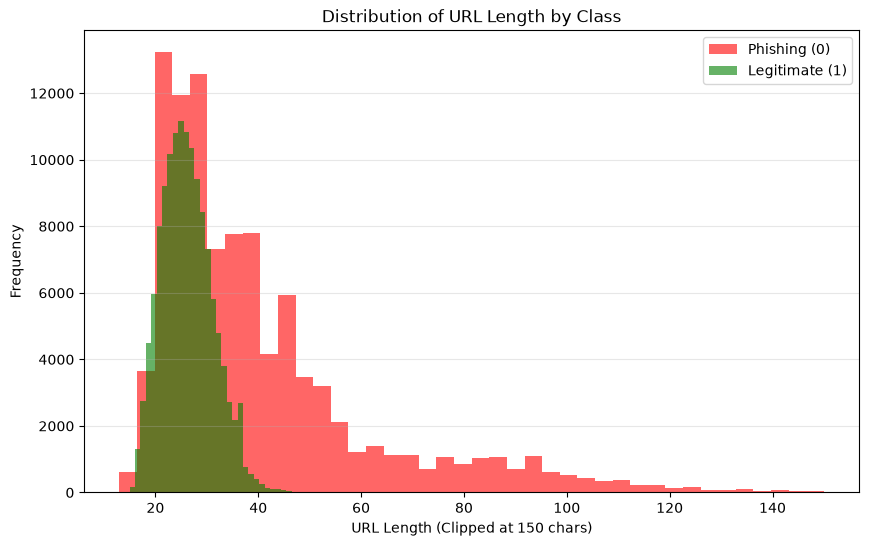

In [31]:
plt.figure(figsize=(10, 6))

plt.hist(
    filtered_df[filtered_df["label"] == 0]["URLLength"],
    bins=40,
    alpha=0.6,
    color='red',
    label="Phishing (0)"
)

plt.hist(
    filtered_df[filtered_df["label"] == 1]["URLLength"],
    bins=40,
    alpha=0.6,
    color='green',
    label="Legitimate (1)"
)

plt.xlabel("URL Length (Clipped at 150 chars)")
plt.ylabel("Frequency")
plt.title("Distribution of URL Length by Class")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

### 2) Label Vs Domain Length

In [32]:
phishing = df[df["label"] == 0]["DomainLength"]
legitimate = df[df["label"] == 1]["DomainLength"]

phishing_counts, bins = np.histogram(phishing, bins=30)
legitimate_counts, _ = np.histogram(legitimate, bins=bins)

distribution = pd.DataFrame({
    "Range_Start": bins[:-1],
    "Range_End": bins[1:],
    "Phishing": phishing_counts,
    "Legitimate": legitimate_counts
})

distribution

,Range_Start,Range_End,Phishing,Legitimate
0,4.000000,7.533333,2288,0
1,7.533333,11.066667,4200,4200
2,11.066667,14.600000,8991,18459
3,14.600000,18.133333,20188,41333
4,18.133333,21.666667,14278,30582
5,21.666667,25.200000,15309,26367
6,25.200000,28.733333,8864,8687
7,28.733333,32.266667,8165,4026
8,32.266667,35.800000,3704,818
9,35.800000,39.333333,4949,305


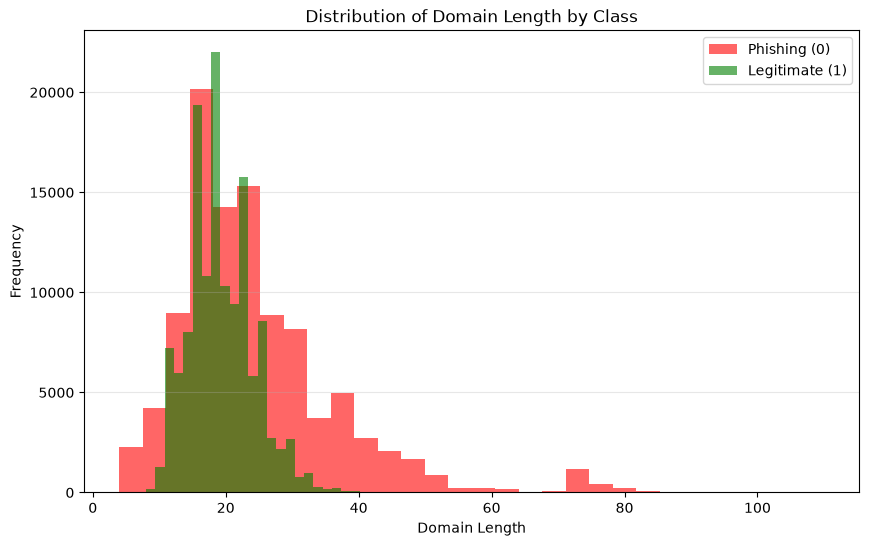

In [33]:
plt.figure(figsize=(10, 6))

plt.hist(
    phishing,
    bins=30,
    alpha=0.6,
    color="red",
    label="Phishing (0)"
)

plt.hist(
    legitimate,
    bins=30,
    alpha=0.6,
    color="green",
    label="Legitimate (1)"
)

plt.xlabel("Domain Length")
plt.ylabel("Frequency")
plt.title("Distribution of Domain Length by Class")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

#### The class-wise distribution indicates an association between domain length and the target class. Legitimate URLs are concentrated at shorter domain lengths, while phishing URLs become more prevalent at larger lengths. The phishing distribution also contains a notable spike around 71–75 characters. These observations suggest that DomainLength may contain predictive information. One important thing is that we even have significant number of Phishing URLs in the range of the Legitimate URLs peak and hence this would be an interesting feature to handle
#### However, its relationship with URLLength should be investigated to assess possible redundancy.

### 3) Label Vs No. of Sub Domains

In [34]:
phishing = df[df["label"] == 0]["NoOfSubDomain"]
legitimate = df[df["label"] == 1]["NoOfSubDomain"]

phishing_counts, bins = np.histogram(phishing, bins=30)
legitimate_counts, _ = np.histogram(legitimate, bins=bins)

distribution = pd.DataFrame({
    "Range_Start": bins[:-1],
    "Range_End": bins[1:],
    "Phishing": phishing_counts,
    "Legitimate": legitimate_counts
})

distribution

,Range_Start,Range_End,Phishing,Legitimate
0,0.000000,0.333333,13983,0
1,0.333333,0.666667,0,0
2,0.666667,1.000000,0,0
3,1.000000,1.333333,63545,114861
4,1.333333,1.666667,0,0
5,1.666667,2.000000,0,0
6,2.000000,2.333333,18115,18238
7,2.333333,2.666667,0,0
8,2.666667,3.000000,0,0
9,3.000000,3.333333,3428,1691


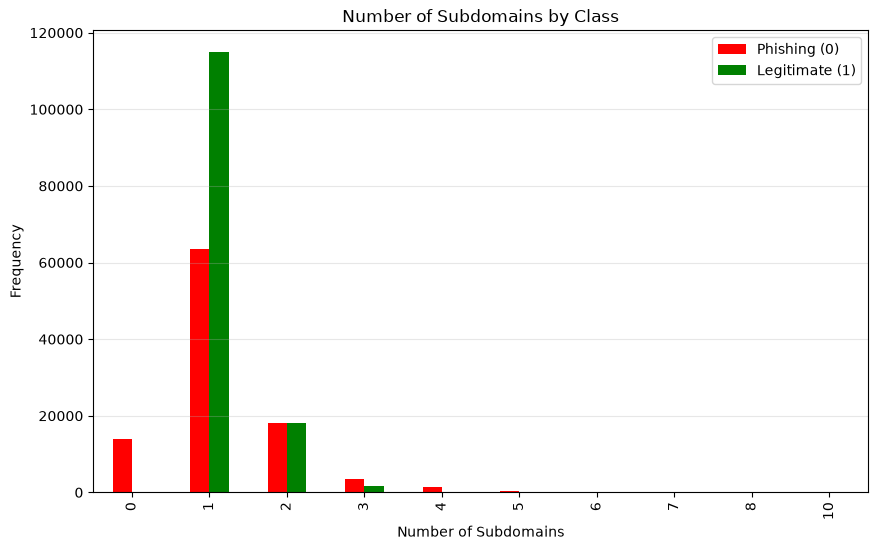

In [35]:
subdomain_counts = df.groupby(
    ["NoOfSubDomain", "label"]
).size().unstack(fill_value=0)

subdomain_counts.plot(
    kind="bar",
    figsize=(10, 6),
    color=["red", "green"]
)

plt.xlabel("Number of Subdomains")
plt.ylabel("Frequency")
plt.title("Number of Subdomains by Class")
plt.legend(["Phishing (0)", "Legitimate (1)"])
plt.grid(axis="y", alpha=0.3)
plt.show()

#### So, we can see that Legitimate URLs are heavily concentrated around one subdomain, with considerably fewer observations at two or three subdomains. In contrast, phishing URLs are distributed across a wider range, from zero to ten subdomains, although most are still concentrated around one or two.

#### As the number of subdomains increases, phishing URLs become more prevalent relative to legitimate URLs. This suggests that NoOfSubDomain may contain useful predictive information. However, since phishing URLs also occur at low subdomain counts, this feature alone is insufficient for reliable classification.


### 4) Label Vs IsDomainIP

In [36]:
distribution = pd.crosstab(
    df["IsDomainIP"],
    df["label"]
)

distribution.columns = ["Phishing", "Legitimate"]
distribution

,Phishing,Legitimate
IsDomainIP,,
0,100307,134850
1,638,0


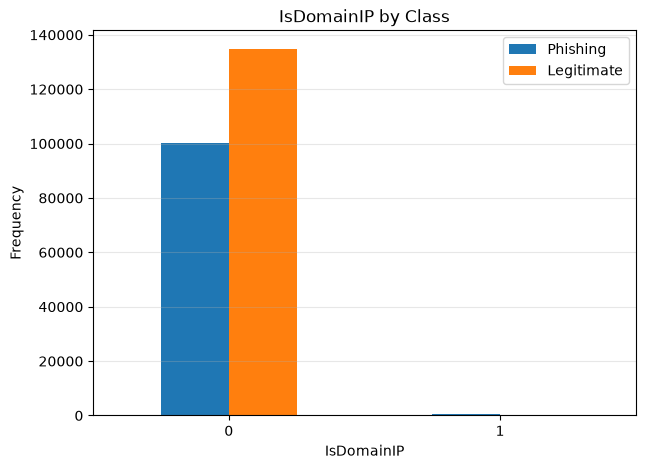

In [37]:
distribution.plot(kind="bar", figsize=(7, 5))

plt.xlabel("IsDomainIP")
plt.ylabel("Frequency")
plt.title("IsDomainIP by Class")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

#### So this means that if in a domain, instead of using domain name --> we are using the IP Address inplace of domain name itself, it is a huge red flag that this link cannot be trusted. But again if it doesn't have the IP Address, then it alone can't tell it is a legitimate URL or not as if we see only 57.34% of URLs are legitimate with no IP in domain name. 

### 5) Label Vs TLDLength

In [38]:
tld_counts = pd.crosstab(
    df["TLDLength"],
    df["label"]
)

tld_counts.columns = ["Phishing", "Legitimate"]

tld_counts

,Phishing,Legitimate
TLDLength,,
2,29346,39915
3,63621,93324
4,6337,1118
5,792,199
6,399,181
7,317,64
8,101,17
9,17,17
10,8,11


In [39]:
### Since above didnt help much, lets see percentage
tld_proportions = pd.crosstab(
    df["TLDLength"],
    df["label"],
    normalize="columns"
) * 100

tld_proportions.columns = ["Phishing", "Legitimate"]

tld_proportions.round(2)

,Phishing,Legitimate
TLDLength,,
2,29.07,29.60
3,63.03,69.21
4,6.28,0.83
5,0.78,0.15
6,0.40,0.13
7,0.31,0.05
8,0.10,0.01
9,0.02,0.01
10,0.01,0.01


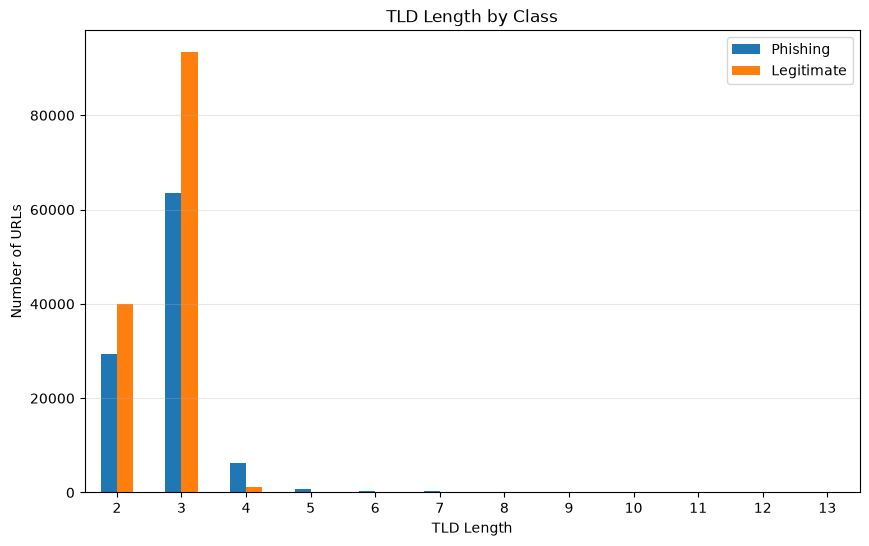

In [40]:
tld_counts.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("TLD Length")
plt.ylabel("Number of URLs")
plt.title("TLD Length by Class")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

#### Both phishing and legitimate URLs are heavily concentrated at TLD lengths of 2 and 3. However, longer TLDs, particularly those with a length of 4, occur more frequently among phishing URLs. This suggests that TLDLength may provide some predictive information, although it cannot reliably distinguish the majority of phishing URLs from legitimate URLs on its own.

## URL obfuscation:

#### Obfuscation means deliberately making something difficult to understand or recognize. Consider:

#### https://google.com@evil.com/login

#### The browser interprets google.com as the username portion, while the actual host is evil.com.

#### Someone looking at the URL might notice google.com and mistakenly think the link is safe.

#### 6) Label Vs HasObfuscation

In [41]:
obfuscation_counts = pd.crosstab(
    df["HasObfuscation"],
    df["label"]
)

obfuscation_counts.columns = ["Phishing", "Legitimate"]

obfuscation_counts

,Phishing,Legitimate
HasObfuscation,,
0,100460,134850
1,485,0


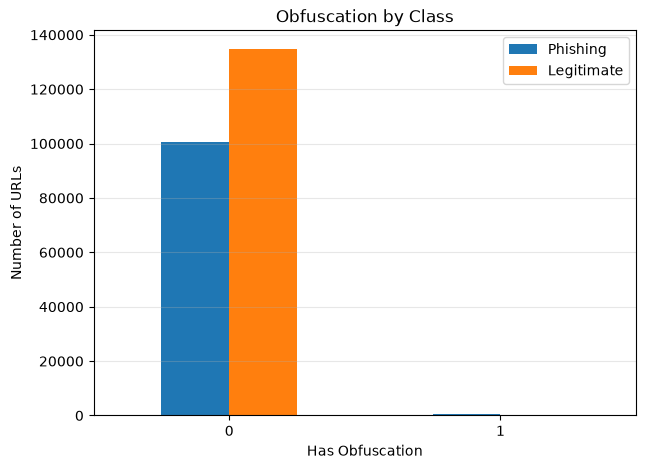

In [42]:
obfuscation_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("Has Obfuscation")
plt.ylabel("Number of URLs")
plt.title("Obfuscation by Class")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

#### Clearly, the attackers have evolved become smarter! We have a very small proportion of attackers with the HasObfuscation = 1. But still we can say All URLs with HasObfuscation = 1 belong to the phishing class in this dataset. However, only 485 out of 100,945 phishing URLs have this feature set to 1. Therefore, detected obfuscation is strongly associated with phishing but occurs in very few phishing URLs. This feature may help identify a small subset of phishing URLs, but it is insufficient for detecting phishing on its own.

### 7) Label Vs NoOfObfuscatedChar

In [43]:
has_obfuscated_chars = df["NoOfObfuscatedChar"] > 0

# Generate cross-tabulation
obfuscation_summary = pd.crosstab(
    has_obfuscated_chars,
    df["label"]
)

# Rename index and columns for clarity
obfuscation_summary.index = ["0 Obfuscated Chars", ">0 Obfuscated Chars"]
obfuscation_summary.columns = ["Phishing", "Legitimate"]

obfuscation_summary

,Phishing,Legitimate
0 Obfuscated Chars,100460,134850
>0 Obfuscated Chars,485,0


#### Same result! This shows us that both of these features are actually redundant. This is because: if it is obfuscated, then its characters > 0 but if it is 0, we cant determine.
#### So basically: HasObfuscation = 0 --> 0 Obfuscated chars and HasObfuscation = 1 --> >0 Obfuscated chars.
#### So both give same result and hence redundant features

### URL character composition:

#### 8) Label Vs NoOfDigitsInURL: 

In [44]:
digits_count = pd.crosstab(
    df["NoOfDegitsInURL"],
    df["label"]
)

digits_count.columns = ["Phishing", "Legitimate"]

digits_count

,Phishing,Legitimate
NoOfDegitsInURL,,
0,53044,131290
1,7204,1612
2,5594,1015
3,5114,594
4,3674,316
...,...,...
865,1,0
1793,1,0
1884,1,0


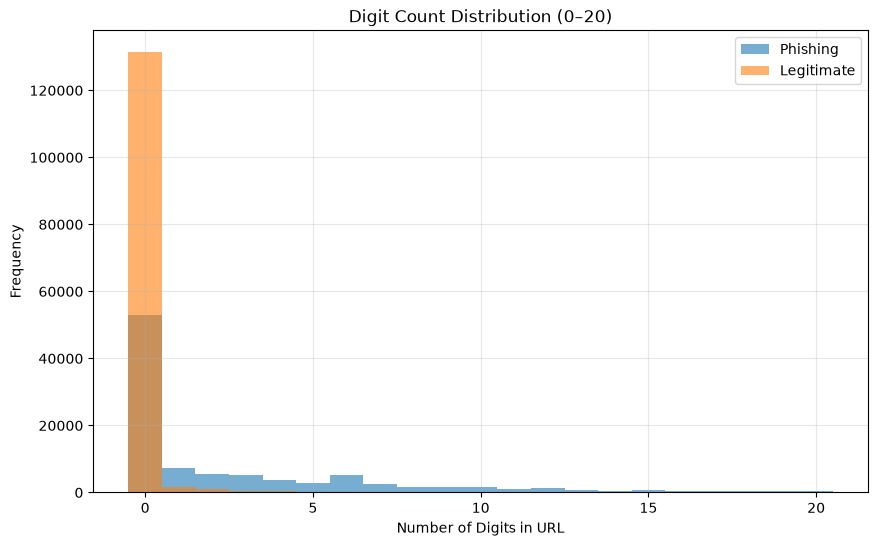

In [45]:
plt.figure(figsize=(10, 6))

for label, name in [(0, "Phishing"), (1, "Legitimate")]:
    values = df.loc[
        (df["label"] == label) & (df["NoOfDegitsInURL"] <= 20),
        "NoOfDegitsInURL"
    ]
    plt.hist(values, bins=21, range=(-0.5, 20.5),
             alpha=0.6, label=name)

plt.xlabel("Number of Digits in URL")
plt.ylabel("Frequency")
plt.title("Digit Count Distribution (0–20)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### So this shows that most of the legitimate URLs are tend to have zero digits in URL. So if some URL has say >5 digits, it is more likely to be Phishing.

#### 9) Label Vs USI: 

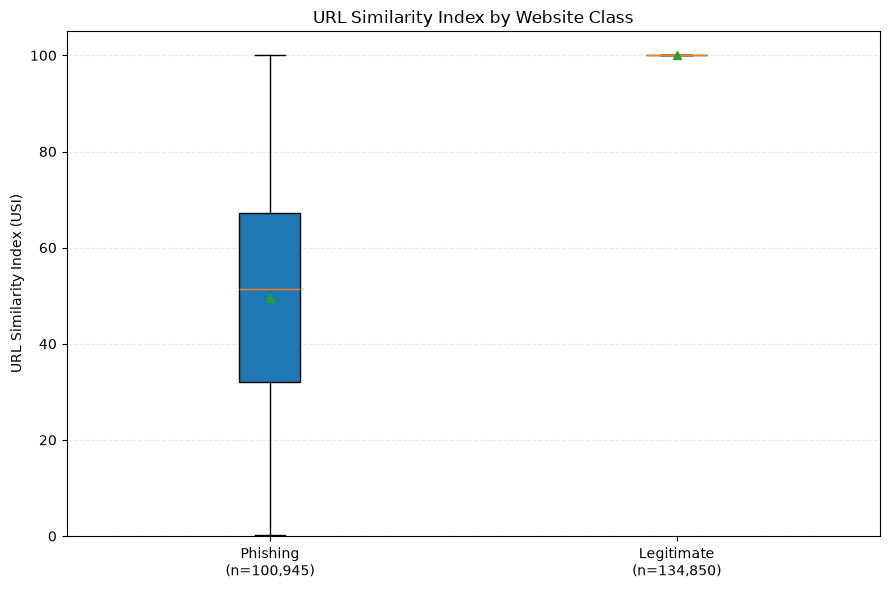

In [51]:
# Split USI scores by class
phishing_usi = df.loc[df["label"] == 0, "URLSimilarityIndex"]
legitimate_usi = df.loc[df["label"] == 1, "URLSimilarityIndex"]

# Create the box plot
plt.figure(figsize=(9, 6))

plt.boxplot(
    [phishing_usi, legitimate_usi],
    tick_labels=["Phishing", "Legitimate"],
    patch_artist=True,
    showmeans=True
)

plt.ylabel("URL Similarity Index (USI)")
plt.title("URL Similarity Index by Website Class")
plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Add sample sizes
plt.xticks(
    [1, 2],
    [
        f"Phishing\n(n={len(phishing_usi):,})",
        f"Legitimate\n(n={len(legitimate_usi):,})"
    ]
)

plt.tight_layout()
plt.show()

#### 10) Label Vs isHTTPS: 

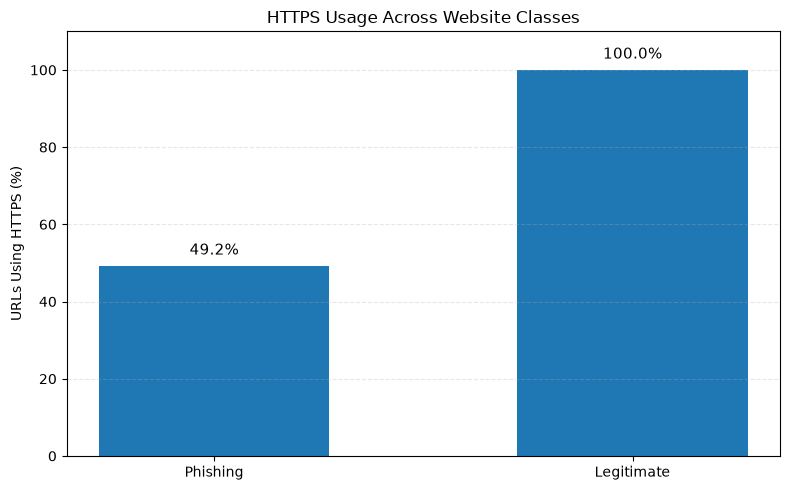

In [53]:
# Calculate HTTPS usage percentage within each class
https_percentages = (
    df.groupby("label")["IsHTTPS"]
    .mean()
    .mul(100)
)

labels = ["Phishing", "Legitimate"]
values = [
    https_percentages.loc[0],
    https_percentages.loc[1]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values, width=0.55)

plt.ylabel("URLs Using HTTPS (%)")
plt.title("HTTPS Usage Across Website Classes")
plt.ylim(0, 110)
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Display percentages above bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()

<hr>

### Correlated Features:

In [46]:
correlation = df[numerical_features].corr()

# Keep only correlations above a chosen threshold
threshold = 0.7

strong_corr = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

strong_corr = strong_corr.stack().reset_index()
strong_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

strong_corr = strong_corr[
    strong_corr["Correlation"].abs() >= threshold
]

strong_corr = strong_corr.sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

strong_corr

,Feature 1,Feature 2,Correlation
1276,DomainTitleMatchScore,URLTitleMatchScore,0.961008
12,URLLength,NoOfLettersInURL,0.956047
14,URLLength,NoOfDegitsInURL,0.835809
716,NoOfDegitsInURL,NoOfEqualsInURL,0.806024
461,HasObfuscation,ObfuscationRatio,0.798791
518,NoOfObfuscatedChar,NoOfAmpersandInURL,0.786451
819,NoOfEqualsInURL,NoOfOtherSpecialCharsInURL,0.784654
19,URLLength,NoOfOtherSpecialCharsInURL,0.782582
719,NoOfDegitsInURL,NoOfOtherSpecialCharsInURL,0.767477
516,NoOfObfuscatedChar,NoOfEqualsInURL,0.754543


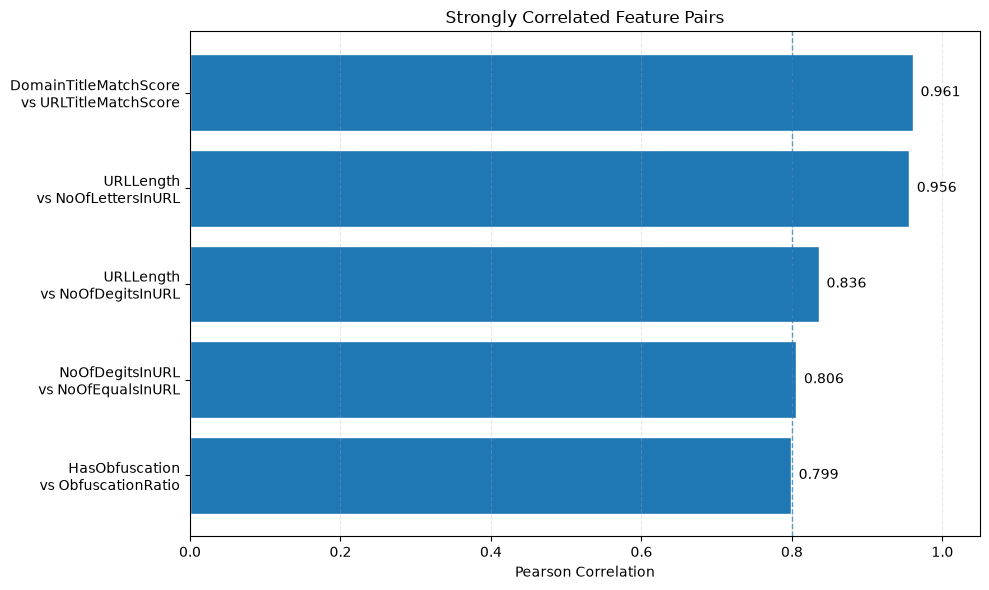

In [55]:
# Select the feature pairs we identified during EDA
feature_pairs = {
    "DomainTitleMatchScore\nvs URLTitleMatchScore": 0.961,
    "URLLength\nvs NoOfLettersInURL": 0.956,
    "URLLength\nvs NoOfDegitsInURL": 0.836,
    "NoOfDegitsInURL\nvs NoOfEqualsInURL": 0.806,
    "HasObfuscation\nvs ObfuscationRatio": 0.799
}

pairs = pd.Series(feature_pairs).sort_values()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    pairs.index,
    pairs.values,
    edgecolor="white"
)

plt.xlabel("Pearson Correlation")
plt.title("Strongly Correlated Feature Pairs")
plt.xlim(0, 1.05)
plt.axvline(0.8, linestyle="--", linewidth=1, alpha=0.7)
plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar, value in zip(bars, pairs.values):
    plt.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

#### So now here, clearly we can see many features are correlated and hence we need to take care of them either before training or with help of regularization 

### Target Correlation:

In [47]:
target_correlation = df[numerical_features].corrwith(df["label"])

target_correlation = target_correlation.sort_values(
    key=abs, ascending=False
)

target_correlation

URLSimilarityIndex            0.860358
HasSocialNet                  0.784255
HasCopyrightInfo              0.743358
HasDescription                0.690232
IsHTTPS                       0.609132
DomainTitleMatchScore         0.584905
HasSubmitButton               0.578561
IsResponsive                  0.548608
URLTitleMatchScore            0.539419
SpacialCharRatioInURL        -0.533537
HasHiddenFields               0.507731
HasFavicon                    0.493711
URLCharProb                   0.469749
CharContinuationRate          0.467735
HasTitle                      0.459725
DegitRatioInURL              -0.432032
Robots                        0.392620
NoOfJS                        0.373500
LetterRatioInURL             -0.367794
Pay                           0.359747
NoOfOtherSpecialCharsInURL   -0.358891
NoOfSelfRef                   0.316211
DomainLength                 -0.283152
NoOfImage                     0.274658
LineOfCode                    0.272257
NoOfExternalRef          

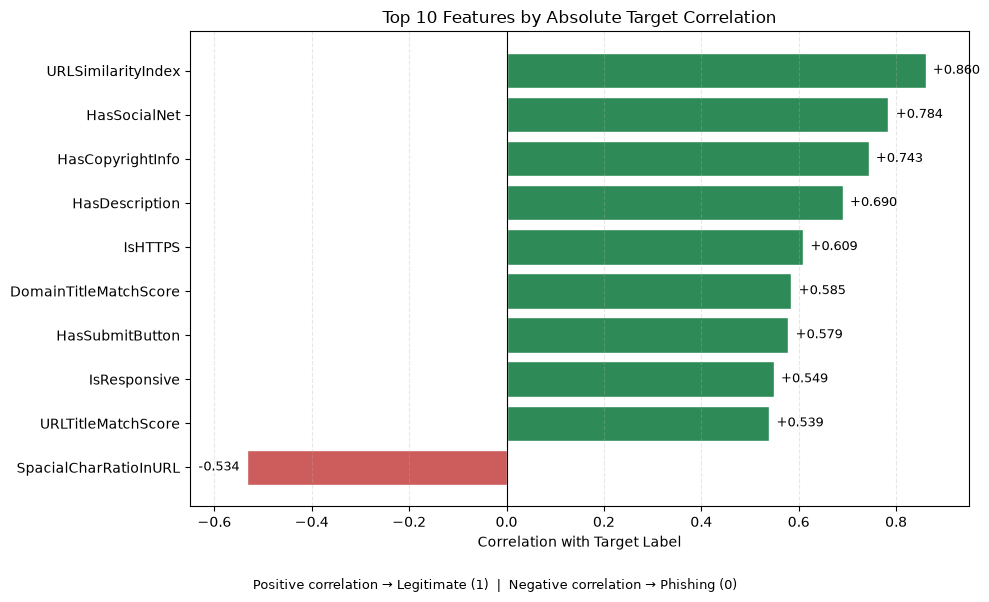

In [49]:
# Select the 10 features with the strongest absolute target correlations
top_10_corr = target_correlation.loc[
    target_correlation.abs().sort_values(ascending=False).head(10).index
].sort_values()

# Plot
plt.figure(figsize=(10, 6))

colors = [
    "seagreen" if value > 0 else "indianred"
    for value in top_10_corr.values
]

plt.barh(
    top_10_corr.index,
    top_10_corr.values,
    color=colors,
    edgecolor="white"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with Target Label")
plt.title("Top 10 Features by Absolute Target Correlation")
plt.xlim(-0.65, 0.95)
plt.grid(axis="x", linestyle="--", alpha=0.3)

# Add correlation values beside each bar
for i, value in enumerate(top_10_corr.values):
    offset = 0.015 if value >= 0 else -0.015
    plt.text(
        value + offset,
        i,
        f"{value:+.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

plt.figtext(
    0.5, 0.01,
    "Positive correlation → Legitimate (1)  |  Negative correlation → Phishing (0)",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

#### So if a correlation is negative, this means that it is associated with Phishing websites as we took Phishing = 0 and if it is positive, it means it is more associated with the Legitimate ones. For exmaple, the above table shows:
#### - URLSimilarityIndex (+0.86): Highly positive because legitimate sites closely match known, safe domain databases.

#### - HasSocialNet (+0.78), HasCopyrightInfo (+0.74), HasDescription (+0.69): Positive because real businesses invest in real web infrastructure (social links, copyright notices, metadata descriptions), whereas phishing pages are bare-bones, temporary scam templates.

#### - SpacialCharRatioInURL (-0.53) & DegitRatioInURL (-0.43): Negative because as special characters and numbers increase, the URL becomes much more likely to be Phishing (0).

#### So this table helps to know how features are related in detecting Phishing

<hr>

### Raw String Feature Detection:

#### For this model, we will initially exclude the raw string features URL, Domain, TLD, and Title and focus on the 50 engineered numerical features.

#### This is because we believe the numerical features cover these string features very well and using them will just result in addition of highly correlated features. For example:
#### - URL --> URLLength, URLSimilarityIndex, URLCharProb, NoOfLettersInURL, LetterRatioInURL etc
#### - Domain --> DomainLength, IsDomainIP, NoOfSubDomain etc.
#### - TLD --> TLDLength, TLDLegitimateProb etc.
#### - Title --> DomainTitleMatchScore, URLTitleMatchScore etc.

#### Although it is possible that the raw string features may contain additional information that is not captured by the engineered features, incorporating them would require additional preprocessing and feature extraction. Therefore, we will leave them out of the initial experiments and consider them as a possible extension.

<hr>